# Can a Risk Matrix Hide a Red Flag?

***Course project – Math Concepts for Developers***

***Author: Yana Stoyanova***

## Contents
1. Introduction
2. The Risk Matrix Model
3. A Simple Example: Can a Single Red Flag Change the Final Rating?
4. Synthetic Customer Data
5. Results
6. Experiment: different weights and an extra rule
7. Conclusion
8. References

## 1. Introduction

Banks and payment companies must assess the money-laundering risk associated with each customer. This is known as the **risk-based approach** and forms a key principle of international and European anti-money-laundering frameworks. Customers assessed as higher risk are subject to enhanced monitoring and additional controls, while lower-risk customers generally require fewer checks.

A common tool used for this purpose is a **risk matrix**. Customers are evaluated across several risk factors, such as geography, customer type, industry, products and services, or distribution channels. Each factor receives a rating of Low, Medium, or High, which can be represented numerically as 1, 2, and 3. These ratings are then combined using a **weighted average** to produce an overall risk score and classification.

A potential limitation of this approach is that a high-risk rating on one factor can be offset by low-risk ratings on other factors. As a result, a customer with a significant warning sign, referred to in this project as a **red flag**, may still receive an overall Low-risk classification.

**Research question**: How often does a customer with at least one High-risk factor receive an overall Low-risk rating, and can a simple additional rule reduce this problem?

**Project objectives**:

- define a simple risk matrix with five risk factors (Section 2);
- analyse mathematically when a single red flag can affect the overall rating (Section 3);
- generate a synthetic population of 1,000 customers (Section 4);
- measure how often red flags are hidden by the risk-scoring model (Section 5);
- evaluate alternative weights and an additional red-flag rule (Section 6).

All customer data used in this project is synthetic and generated randomly. No real customer information is used.

## 2. The risk matrix model

### 2.1 Risk factors

The model uses five risk factors based on categories commonly described in anti-money-laundering guidance, including the EBA Guidelines on ML/TF risk factors. Together, these factors capture different aspects of customer risk:

| Factor risk | What it represents | Example of High risk |
|---|---|---|
| Geography risk | Countries connected to the customer | A country on a FATF high-risk list |
| Customer type risk | The nature and ownership structure of the customer | A company with a complex ownership structure |
| Industry risk | The customer's business activity | A cash-intensive business |
| Product risk| Products and services used by the customer | Large cross-border payments |
| Channel risk | How the customer relationship was established | Non-face-to-face onboarding with limited identity verification and a weak online presence  |

Each factor is assigned a rating of Low, Medium, or High. These ratings are represented numerically as:

- Low = 1
- Medium = 2
- High = 3

### 2.2 Weights

Not all risk factors are assumed to contribute equally to the overall assessment of risk. Therefore, each factor is assigned a weight $w_i$, where the sum of all weights equals 1:

| Factor | Weight |
|---|---|
| Geography | 0.30 |
| Customer type | 0.25 |
| Industry | 0.20 |
| Product | 0.15 |
| Channel | 0.10 |

The weights are modelling assumptions chosen for the purposes of this project.

### 2.3 Risk score

The overall risk score is calculated as a weighted average of the individual factor ratings:

$$S = w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + w_5 x_5$$

where $w_i$ represents the weight assigned to factor $i$, and $x_i$ represents the numerical rating of factor $i$ (1 for Low, 2 for Medium, and 3 for High).

Because the weights sum to 1, the score is always bounded between 1 (all factors rated Low) and 3 (all factors rated High).

As an example, consider a customer who is rated High on Geography, Medium on Industry, and Low on all remaining factors.

$$S = 0.30 * 3 + 0.25 * 1 + 0.20 * 2 + 0.15 * 1 + 0.10 * 1$$

$$S = 0.90 + 0.25 + 0.40 + 0.15 + 0.10 = 1.80$$
    
    
### 2.4 Risk levels

To convert numerical scores into qualitative risk categories, the interval from 1 to 3 is divided into three equal parts:

| Score | Risk level |
|---|---|
| below 1.67 (= 5/3) | Low |
| from 1.67 to below 2.33 (= 7/3) | Medium |
| 2.33 or more | High |

The example customer above receives a score of 1.80 and is therefore classified as **Medium Risk**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from risk_model import (
    FACTORS, LOW_THRESHOLD, HIGH_THRESHOLD,
    generate_customers, risk_score, risk_level, has_red_flag, apply_red_flag_rule,
)

WEIGHTS = {
    "geography": 0.30,
    "customer_type": 0.25,
    "industry": 0.20,
    "product": 0.15,
    "channel": 0.10,
}

# Check the example from Section 2.3
example = pd.DataFrame([{"geography": 3, "customer_type": 1, "industry": 2, "product": 1, "channel": 1}])
example_score = risk_score(example, WEIGHTS)
print("Example score:", round(example_score[0], 2))
print("Example risk level:", risk_level(example_score)[0])

Example score: 1.8
Example risk level: Medium


## 3. A Simple Example: Can a Single Red Flag Change the Final Rating?
Before analysing the synthetic dataset, it is useful to examine a simple example.

Consider a customer who is rated High on exactly one factor (factor $i$) and Low on all remaining factors. The customer's score is:

$S = 3w_i + 1(1-w_i) = 1 + 2w_i$

The term $1-w_i$ represents the combined weight of all remaining factors, which are rated Low.

When does the customer become Medium Risk?

To be classified as at least Medium Risk, the score must satisfy:

$S \geq \frac{5}{3}$

Substituting the formula for $S$:

$1 + 2w_i \geq \frac{5}{3}$

$2w_i \geq \frac{2}{3}$

$w_i \geq \frac{1}{3}$

When does the customer become High Risk?

To be classified as High Risk, the score must satisfy:

$S \geq \frac{7}{3}$

Substituting the formula for $S$:

$1 + 2w_i \geq \frac{7}{3}$

$2w_i \geq \frac{4}{3}$

$w_i \geq \frac{2}{3}$

Interpretation:
The largest weight in this project is 0.30 for Geographic Risk. Since:

$0.30 < \frac{1}{3}$

a customer with one High-risk factor and all remaining factors rated Low will always remain in the Low-risk category.

In other words, a single red flag is not sufficient to move a customer from Low Risk to Medium Risk under the selected weighting scheme. This suggests that a weighted-average model may hide important warning signs when all other factors are rated Low.

The following code verifies this result using the implemented risk-rating model:

In [2]:
rows = []
for factor in FACTORS:
    customer = {f: 1 for f in FACTORS}   # all factors Low
    customer[factor] = 3                 # one factor High
    rows.append(customer)

one_red_flag = pd.DataFrame(rows, index=["High on " + f for f in FACTORS])
one_red_flag["score"] = risk_score(one_red_flag, WEIGHTS).round(2)
one_red_flag["risk level"] = risk_level(one_red_flag["score"])
one_red_flag

,geography,customer_type,industry,product,channel,score,risk level
High on geography,3,1,1,1,1,1.6,Low
High on customer_type,1,3,1,1,1,1.5,Low
High on industry,1,1,3,1,1,1.4,Low
High on product,1,1,1,3,1,1.3,Low
High on channel,1,1,1,1,3,1.2,Low


The results confirm the mathematical analysis. In each case, a customer with only one High-risk factor receives a score of $1 + 2w_i$ and remains classified as Low Risk.

However, real customers rarely have such simple risk profiles. In practice, customers may have a combination of Low-, Medium-, and High-risk factors. To determine how often red flags are hidden in more realistic situations, I analyse a synthetic dataset of customers.

## 4. Data

No real customer data is used in this project. Instead, I generate a synthetic dataset consisting of **1,000 customers**.

For each customer, every risk factor is assigned a rating of Low, Medium, or High according to the probability distributions shown below. These probabilities are modelling assumptions chosen for this project and reflect the expectation that most customers are relatively low risk:

| Factor | P(Low) | P(Medium) | P(High) |
|---|---|---|---|
| Geography | 0.70 | 0.20 | 0.10 |
| Customer type | 0.60 | 0.30 | 0.10 |
| Industry | 0.60 | 0.30 | 0.10 |
| Product | 0.50 | 0.40 | 0.10 |
| Channel | 0.50 | 0.40 | 0.10 |

The ratings for each factor are generated independently. A fixed random seed is used to ensure that the results can be reproduced each time the notebook is executed.

In [3]:
PROBABILITIES = {
    "geography":     [0.70, 0.20, 0.10],
    "customer_type": [0.60, 0.30, 0.10],
    "industry":      [0.60, 0.30, 0.10],
    "product":       [0.50, 0.40, 0.10],
    "channel":       [0.50, 0.40, 0.10],
}

customers = generate_customers(1000, PROBABILITIES, seed=42)
customers.head()

,geography,customer_type,industry,product,channel
0,2,1,2,2,2
1,1,1,1,2,1
2,2,1,3,1,2
3,1,1,2,2,1
4,1,2,1,1,2


As a validation step, I compare the generated ratings with the probability distributions used to create the dataset. The observed proportions should be close to the specified probabilities shown above:

In [4]:
shares = pd.DataFrame({f: customers[f].value_counts(normalize=True).sort_index() for f in FACTORS}).T
shares.columns = ["Low (1)", "Medium (2)", "High (3)"]
shares.round(2)

,Low (1),Medium (2),High (3)
geography,0.70,0.21,0.10
customer_type,0.59,0.30,0.11
industry,0.62,0.28,0.10
product,0.51,0.39,0.10
channel,0.52,0.39,0.08


The observed proportions are close to the specified probabilities, suggesting that the synthetic dataset accurately reflects the assumptions used in the simulation.

## 5. Results

### 5.1 Scores and risk levels

The first step is to calculate the risk score and corresponding risk classification for each customer in the synthetic dataset.

Low       730
Medium    259
High       11
Name: risk_level, dtype: int64


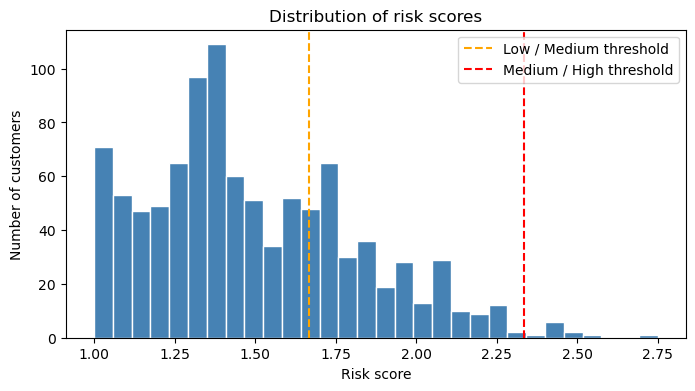

In [5]:
customers["score"] = risk_score(customers, WEIGHTS)
customers["risk_level"] = risk_level(customers["score"])
customers["red_flag"] = has_red_flag(customers)

print(customers["risk_level"].value_counts().reindex(["Low", "Medium", "High"]))

plt.figure(figsize=(8, 4))
plt.hist(customers["score"], bins=30, color="steelblue", edgecolor="white")
plt.axvline(LOW_THRESHOLD, color="orange", linestyle="--", label="Low / Medium threshold")
plt.axvline(HIGH_THRESHOLD, color="red", linestyle="--", label="Medium / High threshold")
plt.xlabel("Risk score")
plt.ylabel("Number of customers")
plt.title("Distribution of risk scores")
plt.legend()
plt.show()

Most customers are classified as Low Risk, while only a small proportion are classified as High Risk. This outcome is consistent with the probability distributions used to generate the synthetic dataset, where High-risk ratings are relatively uncommon.

The histogram shows that most scores are concentrated around the lower and middle parts of the scale, with relatively few customers reaching the High-risk threshold.

### 5.2 How many red flags are hidden?

The main objective of this project is to determine how often a customer with a significant warning sign is still classified as **Low Risk**.

A customer is considered to have a **red flag** if at least one risk factor is rated High. I then calculate the proportion of red-flag customers who nevertheless receive an overall Low-risk classification.

$\text{Hidden red flags} = \frac{\text{Customers with a red flag classified as Low Risk}}{\text{All customers with at least one red flag}}$

In [6]:
red_flag_customers = customers[customers["red_flag"]]
hidden = red_flag_customers[red_flag_customers["risk_level"] == "Low"]

print("Customers with at least one red flag:", len(red_flag_customers))
print("Red-flag customers rated Low Risk:", len(hidden))
print(f"Hidden red flags: {len(hidden) / len(red_flag_customers):.1%}")

Customers with at least one red flag: 398
Red-flag customers rated Low Risk: 164
Hidden red flags: 41.2%


To better understand which risk factors are most affected by this issue, I analyse each factor separately.

For each factor, I identify the customers who are rated High on that factor and calculate the proportion that still receive an overall Low-risk classification.

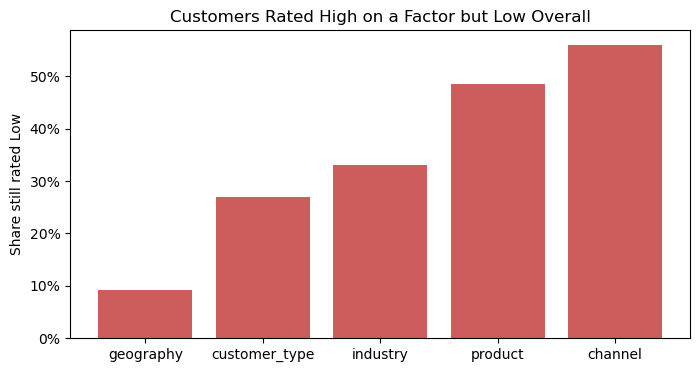

geography         9%
customer_type    27%
industry         33%
product          49%
channel          56%
dtype: object

In [7]:
hidden_by_factor = {}

for factor in FACTORS:
    high_on_factor = customers[customers[factor] == 3]
    hidden_by_factor[factor] = (
        high_on_factor["risk_level"] == "Low"
    ).mean()

hidden_by_factor = pd.Series(hidden_by_factor)

plt.figure(figsize=(8, 4))
plt.bar(hidden_by_factor.index, hidden_by_factor.values, color="indianred")
plt.ylabel("Share still rated Low")
plt.title("Customers Rated High on a Factor but Low Overall")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:.0%}")
)
plt.show()

hidden_by_factor.map("{:.0%}".format)

**The results show a clear relationship between factor weights and the likelihood of a red flag being hidden.**

Only a small proportion of customers rated High on Geographic Risk remain classified as Low Risk. Because Geography has the largest weight in the model, it has the strongest influence on the final score.

In contrast, Product Risk and Channel Risk show the highest proportions of hidden red flags. Since these factors have relatively small weights, a High rating has a limited impact on the overall score and can be offset by low ratings on other factors.

These findings are consistent with the analysis presented in Section 3. Under the selected weighting scheme, a single red flag is often insufficient to move a customer into a higher risk category. Additional Medium- or High-risk ratings on other factors are usually required before the customer is classified as Medium or High Risk.

## 6. Experiment: different weights and an extra rule

### 6.1 Does the problem come from my choice of weights?

A possible explanation for the hidden-red-flag problem is the choice of weights. To test this, I repeat the analysis using equal weights (0.20 for each factor).

From the calculation in Section 3, a single High-risk factor needs a weight of at least 1/3 to guarantee a Medium-risk classification. Since 0.20 is still below that threshold, I expect the problem to persist.

In [8]:
EQUAL_WEIGHTS = {f: 0.2 for f in FACTORS}

levels_equal = risk_level(
    risk_score(customers, EQUAL_WEIGHTS)
)

hidden_equal = (
    levels_equal[customers["red_flag"]] == "Low"
).mean()

hidden_mine = (
    customers.loc[customers["red_flag"], "risk_level"] == "Low"
).mean()

print(f"Hidden red flags with my weights:    {hidden_mine:.1%}")
print(f"Hidden red flags with equal weights: {hidden_equal:.1%}")

Hidden red flags with my weights:    41.2%
Hidden red flags with equal weights: 42.2%


The problem remains even when all factors are assigned equal weights. This suggests that the issue is not caused by the specific weights chosen for the model, but by the **weighted-average approach** itself, which allows low ratings to compensate for a High-risk rating.

### 6.2 Can an Additional Rule Reduce the Problem?

One possible solution is to supplement the weighted-average model with an additional rule:

> **Red-flag rule:** if a customer is High on at least one factor, their overall risk level is at least Medium.

This rule can only increase a customer's risk classification. It may move a customer from Low Risk to Medium Risk, but it never reduces a customer's rating.

To evaluate its effectiveness, I compare three different approaches:


1. **Weighted average** (the original model)
2. **Weighted average + red-flag rule** - the original model with an additional safeguard.
3. **Highest rating**: the overall classification is determined by the customer's highest factor rating. This represents the most conservative approach.

For each method, I evaluate two measures:
- **Hidden red flags**: the proportion of customers with at least one High-risk factor who are still classified as Low Risk. Lower values indicate better detection of potential warning signs,
- **Customers requiring additional review**: the proportion of all customers classified as Medium or High Risk. This serves as a simple proxy for compliance workload, where lower values indicate fewer customers requiring enhanced review.

In [9]:
levels_rule = apply_red_flag_rule(customers["risk_level"], customers)

highest = customers[FACTORS].max(axis=1)
levels_highest = highest.map({1: "Low", 2: "Medium", 3: "High"})

approaches = {
    "Weighted average": customers["risk_level"],
    "Weighted average + red-flag rule": pd.Series(levels_rule, index=customers.index),
    "Highest rating": levels_highest,
}

summary = {}
for name, levels in approaches.items():
    levels = pd.Series(levels).astype(str)
    summary[name] = {
        "hidden red flags": (levels[customers["red_flag"]] == "Low").mean(),
        "customers needing extra checks": (levels != "Low").mean(),
    }

summary = pd.DataFrame(summary).T
summary.applymap("{:.1%}".format)

,hidden red flags,customers needing extra checks
Weighted average,41.2%,27.0%
Weighted average + red-flag rule,0.0%,43.4%
Highest rating,0.0%,92.9%


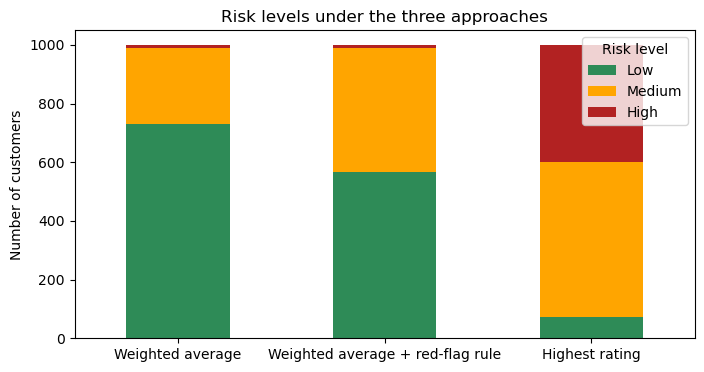

In [10]:
counts = pd.DataFrame({
    name: pd.Series(levels).astype(str).value_counts().reindex(["Low", "Medium", "High"], fill_value=0)
    for name, levels in approaches.items()
}).T

counts.plot(kind="bar", stacked=True, figsize=(8, 4), color=["seagreen", "orange", "firebrick"], rot=0)
plt.ylabel("Number of customers")
plt.title("Risk levels under the three approaches")
plt.legend(title="Risk level")
plt.show()

**Observations:**

The comparison highlights a trade-off between identifying red flags and limiting the number of customers requiring additional review.

The original **weighted-average model** produces the lowest workload, but it also allows a substantial proportion of red flags to remain hidden.

Adding the **red-flag rule** eliminates hidden red flags completely while increasing the proportion of customers requiring additional review from 27.0% to 43.4%.

The **Highest Rating approach** also eliminates hidden red flags, but it results in the highest workload, with 92.9% of customers classified as Medium or High Risk.

Overall, the red-flag rule appears to provide the best balance between risk detection and operational workload.

### 6.3 What Happens if the Risk Thresholds Change?

The previous experiments showed that the hidden-red-flag problem persists under different weighting schemes. Another possible explanation is the **choice of thresholds** used to classify customers as Low, Medium, and High Risk.

In the original model, the interval from 1 to 3 is divided into three equal parts:

Low Risk: score < 1.67

Medium Risk: 1.67 ≤ score < 2.33

High Risk: score ≥ 2.33

To test the sensitivity of the results, I use a stricter set of thresholds and compare the outcomes with the original model.

The objective is to determine whether a different classification scheme can reduce the number of hidden red flags without introducing an excessive compliance workload.

In [11]:
LOW_THRESHOLD_ALT = 1.50
HIGH_THRESHOLD_ALT = 2.25

def risk_level_alt(scores):
    return pd.cut(
        scores,
        bins=[-float("inf"), LOW_THRESHOLD_ALT, HIGH_THRESHOLD_ALT, float("inf")],
        labels=["Low", "Medium", "High"],
        right=False
    )

original_levels = customers["risk_level"]
alt_levels = risk_level_alt(customers["score"])

In [12]:
hidden_original = (
    original_levels[customers["red_flag"]] == "Low"
).mean()

hidden_alt = (
    alt_levels[customers["red_flag"]] == "Low"
).mean()

extra_original = (original_levels != "Low").mean()
extra_alt = (alt_levels != "Low").mean()

comparison = pd.DataFrame({
    "hidden red flags": [hidden_original, hidden_alt],
    "customers needing extra checks": [extra_original, extra_alt],
}, index=["Original thresholds", "Stricter thresholds"])

comparison.applymap("{:.1%}".format)

,hidden red flags,customers needing extra checks
Original thresholds,41.2%,27.0%
Stricter thresholds,16.3%,44.9%


**Observations:**

The results show that **stricter thresholds** significantly reduce the number of hidden red flags.

Under the original thresholds, 41.2% of customers with a red flag are still classified as Low Risk. When stricter thresholds are applied, this proportion falls to 16.3%.

However, this improvement comes at a cost. The proportion of customers requiring additional review increases from 27.0% to 44.9%.

This suggests that **threshold selection** has an important influence on model performance. Stricter thresholds improve risk detection but also increase the compliance workload.

## 7. Conclusion

**Answer to the Research Question** 

This project has shown that a risk matrix based on a weighted-average scoring model can hide important warning signs. A customer with a single High-risk factor may still receive an overall Low-risk classification because low ratings on other factors offset the impact of the red flag.

The mathematical analysis in Section 3 demonstrated that, under the chosen weighting scheme, a single High-risk factor is never sufficient to move a customer into the Medium-risk category. The simulation results confirmed this finding: 41.2% of customers with at least one red flag were still classified as Low Risk.

The problem persisted even when equal weights were applied. This suggests that the issue is not caused by a particular choice of weights, but by the weighted-average approach itself.

**Possible Solutions** 

The experiments in Section 6 showed that adding a simple red-flag rule can eliminate hidden red flags entirely. Under this rule, any customer with at least one High-risk factor must receive a classification of at least Medium Risk.

The threshold experiment produced a similar effect. Stricter thresholds reduced the proportion of hidden red flags from 41.2% to 16.3%, although this improvement came at the cost of a higher compliance workload.

Among the tested approaches, the red-flag rule appears to provide the best balance between effective risk detection and operational efficiency.

**What I learned** 

One of the main lessons from this project is that a seemingly simple mathematical model can produce unintuitive results. A short mathematical calculation was sufficient to predict the behaviour of the model before any data was generated, and the simulation later confirmed those predictions.

More broadly, the project demonstrates how mathematical reasoning can be used not only to build a model, but also to identify its limitations and evaluate possible improvements.

**Limitations:**
- The dataset is entirely synthetic, and the probability distributions, weights, and thresholds are based on modelling assumptions rather than real customer data.
- The risk factors are generated independently, whereas real-world risk factors are often correlated. For example, a high-risk industry may be associated with higher-risk jurisdictions.
- The numerical ratings (1, 2, and 3) are a simplified representation of Low-, Medium-, and High-risk classifications. Alternative scales could produce different results.
- Whether every red flag should automatically lead to a higher risk classification is ultimately a business and regulatory decision rather than a purely mathematical one.

**-Future Work:**
- Introduce dependencies between risk factors to create more realistic customer profiles.
- Test alternative numerical scales for Low-, Medium-, and High-risk ratings.

## 8. References

1. FATF (2012, updated). *International Standards on Combating Money Laundering and the Financing of Terrorism & Proliferation: The FATF Recommendations (2012, as amended June 2026), Recommendation 1. Available at: 

https://www.fatf-gafi.org/content/dam/fatf-gafi/recommendations/fatf-recommendations-2012.pdf

2. European Banking Authority (2021). *Guidelines on customer due diligence and the factors credit and financial institutions should consider when assessing the money laundering and terrorist financing risk (The ML/TF Risk Factors Guidelines), EBA/GL/2021/02 (March 2021, as amended by EBA/GL/2024/01).* Available at: 

https://www.eba.europa.eu/sites/default/files/2024-01/a3e89f4f-fbf3-4bd6-9e07-35f3243555b3/Final%20Amending%20%20Guidelines%20on%20MLTF%20Risk%20Factors.pdf

3. Cox, L. A. Jr. (2008). What's Wrong with Risk Matrices? *Risk Analysis*, 28(2), 497–512. Available at: 

https://doi.org/10.1111/j.1539-6924.2008.01030.x

4. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362. Available at: 

https://www.nature.com/articles/s41586-020-2649-2

5. McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61. Available at: 

https://proceedings.scipy.org/articles/Majora-92bf1922-00a.pdf

6. Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering*, 9(3), 90–95.
7. Matplotlib Development Team. Matplotlib Documentation.Available at: 

https://matplotlib.org/stable/

---

*Use of AI Tools*

AI tools (Claude, by Anthropic) were used during the development of this project to support coding, debugging, and the pres entation of results.

In particular, AI assistance was used when working with Python libraries such as pandas and Matplotlib, including the generation of code for creating the synthetic dataset, producing data visualisations, and refining parts of the written explanations and interpretation of results.

All mathematical reasoning, model design, experiments, analysis, conclusions, and final project decisions were reviewed, adapted, and validated by the author. The project content was not generated automatically and remains the author's own work.